# Naive Bayes

In this notebook, I will use a Naive Bayes classifier to predict expert and plateaued players. Bayes formula is the following:

$$
P(A \mid B) = \frac{P(B \mid A)  P(A)}{P(B)}
$$

Naive Bayes classifiers are a family of simple probabilistic classifiers based on applying Bayes' theorem with strong (naive) independence assumptions between the features. Naive Bayes uses a naive implementation of the Bayes formula that is extremely fast to compute. The assumption is naive because in the real world it is not perfectly accurate, however it works well in practice.

First, I import the CSV:

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")
csv = pd.read_csv('chess_rating_plateau.csv')
print("Read CSV successful")
SEED = 42

Imports successful
Read CSV successful


## Gaussian Naive Bayes

The classifier I will use is a Gaussian Naive Bayes. It is the simplest Naive Bayes classifier that sklearn has to offer and works well with the data. The data is split into train and test data. The classifier is trained on the training set and then evaluated with the test set. Finally, a classification report, confusion matrix and precision recall curve are displayed.

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

drop = ["player_id", "peak_rating", "plateaued", "reached_expert", "deliberate_hours", "age_now"]
features = [c for c in csv.columns if c not in drop]
X = csv[features]

def get_nb(target):
    y = csv[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

    nb = GaussianNB()
    nb.fit(X_train, y_train)

    print(classification_report(y_test, nb.predict(X_test)))
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_estimator(nb, X_test, y_test, ax=ax[0], cmap='Reds')
    ax[0].grid(False)
    ax[0].set_title("Confusion Matrix")
    PrecisionRecallDisplay.from_estimator(nb, X_test, y_test, ax=ax[1])
    ax[1].set_title("Precision Recall Curve")
    plt.show()

## Reached Expert Naive Bayes

I have run a Gaussian Naive Bayes to predict expert players. The scores for predicting an expert are:
- precision - 0.68
- recall - 0.48
- f1-score - 0.57

The confusion matrix displays true vs predicted results visually. Naive Bayes does not seem to be able to predict experts very well, as there is more false negatives than correctly predicted experts. The precision recall curve has an Average Precision of 0.65, which is not a bad score, but it could've been better.

### Comparison vs Decision Trees and Random Forest

Out of the 3 classifiers, Naive Bayes is the worst performing one. The precision is almost as high as the decision tree, however the recall is a lot lower than the others. The f1-score as a result is also lower than the others. Naive Bayes does not offer feature importances data either, meaning that we cannot tell which features contributed the most to a prediction. The comparison between all 3 classifiers is:

| Classifier | Precision | Recall | F1-Score | Average Precision |
| --- | --- | --- | --- | --- |
| Decision Tree | 0.72 | 0.64 | 0.68 | 0.75 |
| Random Forest | 0.83 | 0.68 | 0.75 | 0.85 |
| Naive Bayes | 0.68 | 0.48 | 0.57 | 0.65 |

              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7200
           1       0.68      0.48      0.57      1800

    accuracy                           0.85      9000
   macro avg       0.78      0.71      0.74      9000
weighted avg       0.84      0.85      0.84      9000



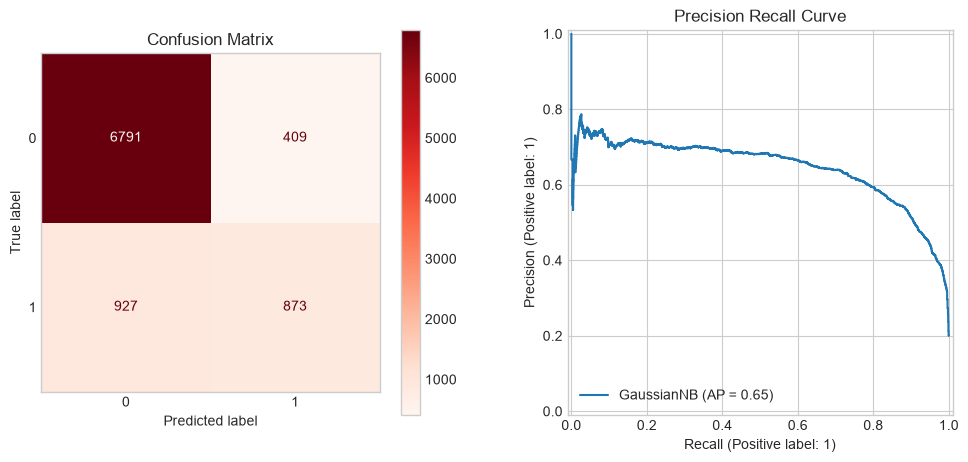

In [8]:
get_nb('reached_expert')

## Plateaued Naive Bayes

I have run a Gaussian Naive Bayes to predict plateaued players. The scores for predicting a plateaued player are:
- precision - 0.54
- recall - 0.35
- f1-score - 0.42

The confusion matrix displays true vs predicted results visually. Naive Bayes does not seem to be able to predict plateaued players correctly most of the time, as there is a substantial amount of false positives and false negatives. The precision recall curve has an Average Precision of 0.50, meaning that on average half of its predictions are correct, which is a bad score.

### Comparison vs Decision Trees and Random Forest

All 3 classifiers yield very similar results to each other. Naive Bayes performs slightly better than random forest, but slightly worse than decision trees. All classifiers are equally bad at trying to predict plateaued players. The comparison between all 3 classifiers is:

| Classifier | Precision | Recall | F1-Score | Average Precision |
| --- | --- | --- | --- | --- |
| Decision Tree | 0.55 | 0.33 | 0.41 | 0.50 |
| Random Forest | 0.55 | 0.30 | 0.38 | 0.50 |
| Naive Bayes | 0.54 | 0.35 | 0.42 | 0.50 |


              precision    recall  f1-score   support

           0       0.66      0.81      0.73      5505
           1       0.54      0.35      0.42      3495

    accuracy                           0.63      9000
   macro avg       0.60      0.58      0.58      9000
weighted avg       0.61      0.63      0.61      9000



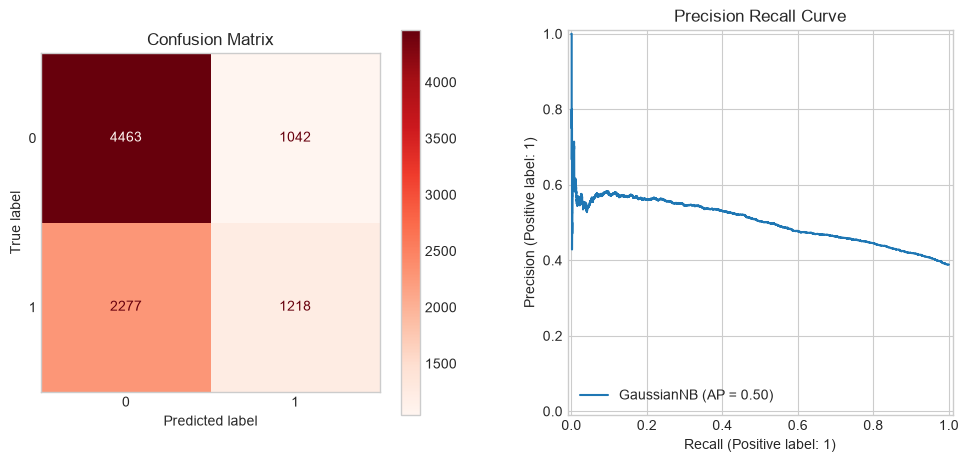

In [ ]:
get_nb('plateaued')

## Conclusion

Naive Bayes uses a naive assumption of the Bayes theorem that assumes that the features are independendent from each other. If that were the case, Naive Bayes would be the optimal classifier. However, it is not the case as in the real world and in this dataset, some features are correlated with each other. We use the naive assumption as its exponentially easier to compute and yields decent results.

Naive Bayes can be useful as a baseline for other classifiers in this dataset. It can yield a simple, but sometimes weak, prediction that can be improved further with Decision Trees or Random Forests. 